# 05 — Final Evaluation (cu best params din Optuna)

**Pași:**
1. Citește `best_params.json` din Tier 1 și Tier 5 (notebook 03 + 04)
2. Strategie: Tier 1 folosește params Tier 1; Tier 2-5 folosesc params Tier 5
3. Re-train cu best params (mai multe epoci, fără pruning)
4. Evaluează pe TEST set + per-source breakdown (HAM/BCN/MSK)
5. Salvează `test_results.json`, `test_predictions.csv`, plots

**Compute estimat:** ~1h × 5 tier-uri = **~5h total**.

**Output:** `experiments/inceptionresnetv2/tier{1-5}/D_final/`


## 1. Setup


In [2]:
from google.colab import drive
drive.mount('/content/drive')
print('Drive mounted')

Mounted at /content/drive
Drive mounted


In [3]:
import os
import json
import time
import random
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import backend as K
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    precision_recall_fscore_support,
)

# ─── REPRODUCIBILITY ───
SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
tf.keras.utils.set_random_seed(SEED)

print(f'TF: {tf.__version__}')
print(f'GPU: {tf.config.list_physical_devices("GPU")}')
print(f'Seed: {SEED}')

TF: 2.20.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Seed: 42


In [4]:
# ─── PATHS ───
DRIVE_BASE = Path('/content/drive/MyDrive/Thesis')
PIPELINE_DIR = DRIVE_BASE / 'pipeline_outputs'

TFRECORDS_DIR = PIPELINE_DIR / 'step4_tfrecords'   # val/, test/, tier5/
STEP2_DIR = PIPELINE_DIR / 'step2'                 # tier{N}_train.csv
EXPERIMENTS_DIR = DRIVE_BASE / 'experiments' / 'inceptionresnetv2'
EXPERIMENTS_DIR.mkdir(parents=True, exist_ok=True)

# ─── HYPERPARAMETERS ───
IMG_SIZE = 224
NUM_CLASSES = 7
BATCH_SIZE = 32
DENSE1_UNITS = 1024
DENSE2_UNITS = 256
DROPOUT_RATE = 0.3
ROTATION_MAX_DEG = 20
ZOOM_RANGE = 0.1

PAPER_TRAINABLE_PARAMS = 1_840_647

# ─── LABELS ───
IDX_TO_LABEL = {0: 'akiec', 1: 'bcc', 2: 'bkl', 3: 'df', 4: 'mel', 5: 'nv', 6: 'vasc'}
CLASS_NAMES = [IDX_TO_LABEL[i] for i in range(NUM_CLASSES)]

print(f'TFRecords:   {TFRECORDS_DIR.exists()} {TFRECORDS_DIR}')
print(f'Step2:       {STEP2_DIR.exists()} {STEP2_DIR}')
print(f'Experiments: {EXPERIMENTS_DIR}')

for split in ['val', 'test', 'tier5']:
    d = TFRECORDS_DIR / split
    if d.exists():
        shards = sorted(d.glob('*.tfrecord'))
        print(f'  {split}: {len(shards)} shards')
    else:
        print(f'  [WARNING] {split}/ missing!')

TFRecords:   True /content/drive/MyDrive/Thesis/pipeline_outputs/step4_tfrecords
Step2:       True /content/drive/MyDrive/Thesis/pipeline_outputs/step2
Experiments: /content/drive/MyDrive/Thesis/experiments/inceptionresnetv2
  val: 3 shards
  test: 3 shards
  tier5: 21 shards


## 2. Data pipeline


In [5]:
FEATURE_DESC = {
    'image_id':    tf.io.FixedLenFeature([], tf.string),
    'label':       tf.io.FixedLenFeature([], tf.int64),
    'lesion_id':   tf.io.FixedLenFeature([], tf.string),
    'source':      tf.io.FixedLenFeature([], tf.string),
    'image_bytes': tf.io.FixedLenFeature([], tf.string),
}


def parse_example(example_proto):
    return tf.io.parse_single_example(example_proto, FEATURE_DESC)


def decode_image(parsed):
    img = tf.io.decode_jpeg(parsed['image_bytes'], channels=3)
    img = tf.image.resize(img, [IMG_SIZE, IMG_SIZE])
    img = tf.cast(img, tf.float32) / 255.0
    return img, parsed['label'], parsed['lesion_id']


def decode_with_source(parsed):
    img = tf.io.decode_jpeg(parsed['image_bytes'], channels=3)
    img = tf.image.resize(img, [IMG_SIZE, IMG_SIZE])
    img = tf.cast(img, tf.float32) / 255.0
    return img, parsed['label'], parsed['source']


def get_split_files(split_name):
    pattern = str(TFRECORDS_DIR / split_name / '*.tfrecord')
    files = sorted(tf.io.gfile.glob(pattern))
    if not files:
        raise FileNotFoundError(f'No TFRecords found for split: {split_name}')
    return files


TRAIN_FILES = get_split_files('tier5')
VAL_FILES = get_split_files('val')
TEST_FILES = get_split_files('test')

print(f'Train pool: {len(TRAIN_FILES)} shards')
print(f'Val:        {len(VAL_FILES)} shards')
print(f'Test:       {len(TEST_FILES)} shards')

Train pool: 21 shards
Val:        3 shards
Test:       3 shards


In [6]:
def get_tier_lesion_ids(tier):
    if tier == 5:
        return None
    csv_path = STEP2_DIR / f'tier{tier}_train.csv'
    df = pd.read_csv(csv_path)
    return set(df['lesion_id'].astype(str).tolist())


def make_lesion_filter(allowed_ids):
    keys = tf.constant(sorted(list(allowed_ids)), dtype=tf.string)
    values = tf.ones(len(allowed_ids), dtype=tf.int32)
    return tf.lookup.StaticHashTable(
        tf.lookup.KeyValueTensorInitializer(keys, values),
        default_value=0,
    )


for t in [1, 2, 3, 4, 5]:
    ids = get_tier_lesion_ids(t)
    if ids is None:
        print(f'Tier {t}: no filter (full tier5)')
    else:
        print(f'Tier {t}: {len(ids):,} lesion_ids')

Tier 1: 5,987 lesion_ids
Tier 2: 7,276 lesion_ids
Tier 3: 8,565 lesion_ids
Tier 4: 9,855 lesion_ids
Tier 5: no filter (full tier5)


In [7]:
# ─── Augmentation pure tf.image + scipy (fără SeedGenerator → fără bug CUDA) ───
# Bug istoric: tf.keras.layers.RandomFlip/RandomRotation cauzează
# CUDA_ERROR_INVALID_HANDLE când SeedGenerator se inițializează înainte de GPU.
# Soluția: folosim tf.image (in-graph, GPU) + scipy via tf.numpy_function (CPU).
from scipy.ndimage import rotate as scipy_rotate

def _random_rotate_np(image_np, max_deg):
    """Rotație random pe CPU cu scipy."""
    import numpy as np
    angle = np.random.uniform(-max_deg, max_deg)
    return scipy_rotate(
        image_np, angle, reshape=False, order=1, mode='reflect',
    ).astype(np.float32)


def augment_image(image, rotation_deg=ROTATION_MAX_DEG, zoom=ZOOM_RANGE):
    """Augmentation: flip + rotation ±rotation_deg° + zoom ±zoom (per Nawaz spec)."""
    # Flip horizontal + vertical
    image = tf.image.random_flip_left_right(image)
    image = tf.image.random_flip_up_down(image)

    # Rotation via scipy (CPU side, robust)
    image = tf.numpy_function(
        func=lambda x: _random_rotate_np(x, rotation_deg),
        inp=[image],
        Tout=tf.float32,
    )
    image.set_shape([None, None, 3])

    # Zoom prin resize + center crop
    zoom_factor = tf.random.uniform([], 1.0 - zoom, 1.0 + zoom)
    new_size = tf.cast(tf.cast(IMG_SIZE, tf.float32) / zoom_factor, tf.int32)
    image = tf.image.resize(image, [new_size, new_size])
    image = tf.image.resize_with_crop_or_pad(image, IMG_SIZE, IMG_SIZE)

    image = tf.clip_by_value(image, 0.0, 1.0)
    return image


def preprocess_for_model(img_01):
    """Input [0,1] (after /255). Apply per-model preprocessing.

    InceptionResNetV2 folosește tf.keras.applications.inception_resnet_v2.preprocess_input
    care așteaptă input în range [0, 255] și returnează range specific arhitecturii.
    """
    img_255 = img_01 * 255.0
    return tf.keras.applications.inception_resnet_v2.preprocess_input(img_255)


print('Augmentation + preprocessing definite')

Augmentation + preprocessing definite


In [8]:
def build_train_ds(tier, rotation_deg=ROTATION_MAX_DEG, zoom=ZOOM_RANGE):
    """Train ds — repeat + filter pe lesion_id pentru tier1-4."""
    allowed_ids = get_tier_lesion_ids(tier)

    # Augmentation layer per call (allows different rotation/zoom in Optuna)
    # NOTE: augmentation customized per call ignored — folosim augment_image global
    # cu rotation_deg și zoom din parametri
    aug = lambda img, training=True: augment_image(
        img, rotation_deg=rotation_deg, zoom=zoom,
    )
    ds = tf.data.TFRecordDataset(TRAIN_FILES, num_parallel_reads=tf.data.AUTOTUNE)
    ds = ds.map(parse_example, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.map(decode_image, num_parallel_calls=tf.data.AUTOTUNE)

    if allowed_ids is not None:
        table = make_lesion_filter(allowed_ids)
        ds = ds.filter(lambda img, lbl, lid: tf.equal(table.lookup(lid), 1))

    ds = ds.map(lambda img, lbl, lid: (img, lbl), num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.repeat()
    ds = ds.shuffle(buffer_size=2000, seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(
        lambda img, lbl: (aug(img, training=True), lbl),
        num_parallel_calls=tf.data.AUTOTUNE,
    )
    ds = ds.map(
        lambda img, lbl: (preprocess_for_model(img), lbl),
        num_parallel_calls=tf.data.AUTOTUNE,
    )
    ds = ds.batch(BATCH_SIZE, drop_remainder=True)
    ds = ds.prefetch(tf.data.AUTOTUNE)
    return ds


def build_eval_ds(files, with_source=False):
    ds = tf.data.TFRecordDataset(files, num_parallel_reads=tf.data.AUTOTUNE)
    ds = ds.map(parse_example, num_parallel_calls=tf.data.AUTOTUNE)
    if with_source:
        ds = ds.map(decode_with_source, num_parallel_calls=tf.data.AUTOTUNE)
        ds = ds.map(
            lambda img, lbl, src: (preprocess_for_model(img), lbl, src),
            num_parallel_calls=tf.data.AUTOTUNE,
        )
    else:
        ds = ds.map(decode_image, num_parallel_calls=tf.data.AUTOTUNE)
        ds = ds.map(lambda img, lbl, lid: (img, lbl), num_parallel_calls=tf.data.AUTOTUNE)
        ds = ds.map(
            lambda img, lbl: (preprocess_for_model(img), lbl),
            num_parallel_calls=tf.data.AUTOTUNE,
        )
    ds = ds.batch(BATCH_SIZE, drop_remainder=False)
    ds = ds.prefetch(tf.data.AUTOTUNE)
    return ds


print('Dataset builders definite')

Dataset builders definite


In [9]:
def count_tier_samples(tier):
    allowed_ids = get_tier_lesion_ids(tier)
    ds = tf.data.TFRecordDataset(TRAIN_FILES, num_parallel_reads=tf.data.AUTOTUNE)
    ds = ds.map(parse_example, num_parallel_calls=tf.data.AUTOTUNE)
    if allowed_ids is not None:
        table = make_lesion_filter(allowed_ids)
        ds = ds.filter(lambda x: tf.equal(table.lookup(x['lesion_id']), 1))
    counter = Counter()
    for ex in ds:
        counter[int(ex['label'].numpy())] += 1
    return dict(counter)


TIER_DISTRIBUTIONS = {}
print('Counting samples per tier (~1-2 min):')
for t in [1, 2, 3, 4, 5]:
    dist = count_tier_samples(t)
    TIER_DISTRIBUTIONS[t] = dist
    total = sum(dist.values())
    print(f'  Tier {t}: {total:>6,} samples')

val_count = sum(1 for _ in tf.data.TFRecordDataset(VAL_FILES))
test_count = sum(1 for _ in tf.data.TFRecordDataset(TEST_FILES))
print(f'\nVal:  {val_count:,}')
print(f'Test: {test_count:,}')

Counting samples per tier (~1-2 min):
  Tier 1:  8,042 samples
  Tier 2: 10,996 samples
  Tier 3: 14,061 samples
  Tier 4: 17,300 samples
  Tier 5: 20,299 samples

Val:  2,519
Test: 2,513


## 3. Focal loss + Model + Eval


In [10]:
def compute_alpha_inverse_frequency(distribution, normalize=True):
    """sklearn 'balanced' alpha. Output: array de shape (num_classes,)."""
    counts = np.array([distribution[i] for i in range(NUM_CLASSES)], dtype=np.float32)
    total = counts.sum()
    alpha = total / (NUM_CLASSES * counts)
    if normalize:
        alpha = alpha / alpha.max()
    return alpha


def categorical_focal_loss(alpha, gamma=2.0):
    """Categorical focal loss cu alpha per clasa.

    FL(p_t) = -α_t · (1 - p_t)^γ · log(p_t)

    Folosim sparse labels (int) → one-hot intern.
    """
    alpha = tf.constant(alpha, dtype=tf.float32)

    def loss(y_true, y_pred):
        # y_true vine ca int64 (labels), y_pred ca probabilități softmax
        y_true_oh = tf.one_hot(tf.cast(y_true, tf.int32), depth=NUM_CLASSES)
        y_pred = tf.clip_by_value(y_pred, K.epsilon(), 1.0 - K.epsilon())
        ce = -y_true_oh * tf.math.log(y_pred)
        focal_weight = tf.pow(1.0 - y_pred, gamma)
        weighted_loss = alpha * focal_weight * ce
        return tf.reduce_mean(tf.reduce_sum(weighted_loss, axis=-1))

    return loss


# Sanity check pe Tier 5
alpha_t5 = compute_alpha_inverse_frequency(TIER_DISTRIBUTIONS[5])
print('Alpha for Tier 5 (normalized to max=1):')
for i, name in enumerate(CLASS_NAMES):
    print(f'  {name}: {alpha_t5[i]:.4f}')

Alpha for Tier 5 (normalized to max=1):
  akiec: 0.1544
  bcc: 0.0691
  bkl: 0.0865
  df: 1.0000
  mel: 0.0507
  nv: 0.0179
  vasc: 0.8804


In [11]:
def build_inceptionresnetv2(
    dense1=DENSE1_UNITS, dense2=DENSE2_UNITS, dropout=DROPOUT_RATE,
    base_trainable=False, verbose=True,
):
    """Strict Nawaz Table 5 — Total 56,179,943 / Trainable 1,840,647 (base frozen)."""
    inputs = tf.keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))

    base = tf.keras.applications.InceptionResNetV2(
        include_top=False,
        weights='imagenet',
        input_shape=(IMG_SIZE, IMG_SIZE, 3),
    )
    base.trainable = base_trainable

    # CRITICAL: BN-urile din bază înghețate COMPLET (gamma+beta non-trainable).
    for layer in base.layers:
        if isinstance(layer, tf.keras.layers.BatchNormalization):
            layer.trainable = False

    x = base(inputs, training=False)
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dense(dense1, activation='relu')(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Dropout(dropout)(x)
    x = tf.keras.layers.Dense(dense2, activation='relu')(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Dropout(dropout)(x)
    outputs = tf.keras.layers.Dense(NUM_CLASSES, activation='softmax')(x)

    model = tf.keras.Model(inputs, outputs, name='InceptionResNetV2')
    model.base_model = base

    if verbose:
        total = model.count_params()
        trainable = sum(tf.size(w).numpy() for w in model.trainable_weights)
        print(f'  Total: {total:,} | Trainable: {trainable:,}')
    return model


def set_phase_1(model):
    """Phase 1: head only."""
    model.base_model.trainable = False
    trainable = sum(tf.size(w).numpy() for w in model.trainable_weights)
    print(f'[Phase 1] Trainable: {trainable:,}')


def set_phase_2(model):
    """Phase 2: full unfreeze with BN STILL frozen."""
    model.base_model.trainable = True
    for layer in model.base_model.layers:
        if isinstance(layer, tf.keras.layers.BatchNormalization):
            layer.trainable = False
    trainable = sum(tf.size(w).numpy() for w in model.trainable_weights)
    print(f'[Phase 2] Trainable: {trainable:,} (BN-uri din bază înghețate)')


_test = build_inceptionresnetv2()
del _test
tf.keras.backend.clear_session()

219055592/219055592 ━━━━━━━━━━━━━━━━━━━━ 12s 0us/step
  Total: 56,179,943 | Trainable: 1,840,647


In [12]:
def evaluate_model(model, ds, label='test'):
    print(f'Evaluating on {label}...')
    y_true, y_pred, y_proba = [], [], []
    for imgs, labels in ds:
        preds = model.predict(imgs, verbose=0)
        y_proba.extend(preds)
        y_pred.extend(np.argmax(preds, axis=1))
        y_true.extend(labels.numpy())

    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    y_proba = np.array(y_proba)

    acc = float(np.mean(y_true == y_pred))
    prec, rec, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average='weighted', zero_division=0,
    )
    macro_f1 = precision_recall_fscore_support(
        y_true, y_pred, average='macro', zero_division=0,
    )[2]
    try:
        auc = float(roc_auc_score(y_true, y_proba, multi_class='ovr', average='weighted'))
    except Exception:
        auc = float('nan')

    cm = confusion_matrix(y_true, y_pred, labels=list(range(NUM_CLASSES)))
    report = classification_report(
        y_true, y_pred, target_names=CLASS_NAMES, zero_division=0,
    )

    print(f'  Accuracy:    {acc*100:.2f}%')
    print(f'  Precision:   {prec:.4f}')
    print(f'  Recall:      {rec:.4f}')
    print(f'  Weighted F1: {f1:.4f}')
    print(f'  Macro F1:    {macro_f1:.4f}')
    print(f'  AUC (ovr):   {auc:.4f}')

    return {
        'accuracy': acc, 'precision': float(prec), 'recall': float(rec),
        'weighted_f1': float(f1), 'macro_f1': float(macro_f1), 'auc': auc,
        'confusion_matrix': cm.tolist(),
        'classification_report': report,
        'y_true': y_true.tolist(), 'y_pred': y_pred.tolist(),
        'y_proba': y_proba.tolist(),
    }

## 4. Load best params din Optuna


In [13]:
best_params = {}
for tier in [1, 5]:
    bp_path = EXPERIMENTS_DIR / f'tier{tier}' / 'C_optuna' / 'best_params.json'
    if bp_path.exists():
        with open(bp_path) as f:
            best_params[tier] = json.load(f)
        print(f'Tier {tier}: val_acc = {best_params[tier]["best_value"]:.4f}')
        for k, v in best_params[tier]['best_params'].items():
            print(f'  {k}: {v}')
        print()
    else:
        print(f'⚠ Tier {tier} Optuna results NOT found at {bp_path}')
        print(f'  Run notebook {"03" if tier == 1 else "04"} first!')
        best_params[tier] = None


def get_params_for_tier(tier):
    """Strategie: Tier 1 → params Tier 1; Tier 2-5 → params Tier 5."""
    if tier == 1 and best_params.get(1):
        return best_params[1]['best_params']
    if best_params.get(5):
        return best_params[5]['best_params']
    raise ValueError(f'No best_params available for tier {tier}')


Tier 1: val_acc = 0.4645
  learning_rate: 0.0009943336796094002
  dropout: 0.468116917403246
  dense1_units: 1024
  dense2_units: 512
  rotation_max: 30
  zoom_range: 0.13283729155936824
  focal_gamma: 1.6855985765326325

Tier 5: val_acc = 0.5629
  learning_rate: 1.6379674586081077e-05
  dropout: 0.3539871612489546
  dense1_units: 2048
  dense2_units: 512
  rotation_max: 30
  zoom_range: 0.10096687016643235
  focal_gamma: 1.747955411483169



## 5. Per-source evaluation helper


In [14]:
def evaluate_per_source(model, test_files):
    """Evaluează test set și returnează metrici per-source (HAM/BCN/MSK)."""
    print('Collecting predictions cu source labels...')
    ds = build_eval_ds(test_files, with_source=True)

    all_y_true, all_y_pred, all_y_proba, all_sources = [], [], [], []

    for imgs, labels, sources in ds:
        preds = model.predict(imgs, verbose=0)
        all_y_proba.extend(preds)
        all_y_pred.extend(np.argmax(preds, axis=1))
        all_y_true.extend(labels.numpy())
        all_sources.extend([s.decode('utf-8') for s in sources.numpy()])

    df = pd.DataFrame({
        'y_true': all_y_true,
        'y_pred': all_y_pred,
        'source': all_sources,
    })
    for i, name in enumerate(CLASS_NAMES):
        df[f'prob_{name}'] = [p[i] for p in all_y_proba]

    # Per-source metrics
    per_source = {}
    for src in ['HAM10000', 'BCN_20000', 'MSK']:
        s_df = df[df['source'] == src]
        if len(s_df) == 0:
            per_source[src] = {'n_samples': 0}
            continue

        y_t = s_df['y_true'].values
        y_p = s_df['y_pred'].values
        prec, rec, f1, _ = precision_recall_fscore_support(
            y_t, y_p, average='macro', zero_division=0,
        )
        per_source[src] = {
            'n_samples': int(len(s_df)),
            'accuracy': float(np.mean(y_t == y_p)),
            'macro_f1': float(f1),
            'precision': float(prec),
            'recall': float(rec),
        }

    return df, per_source


## 6. Final training + test evaluation


In [15]:
FINAL_CONFIG = {
    'epochs': 30,
    'patience': 8,
    'focal_gamma_default': 2.0,  # fallback dacă Optuna nu l-a tunat
}

def train_tier_final(tier):
    tier_dir = EXPERIMENTS_DIR / f'tier{tier}' / 'D_final'
    tier_dir.mkdir(parents=True, exist_ok=True)

    results_path = tier_dir / 'test_results.json'
    if results_path.exists():
        print(f'\n⏭  Tier {tier} final already done, loading...')
        with open(results_path) as f:
            return json.load(f)

    print(f'\n{"#"*70}\n# TIER {tier} — FINAL (best Optuna params)\n{"#"*70}')

    try:
        params = get_params_for_tier(tier)
    except ValueError as e:
        print(f'  Skipping: {e}')
        return None

    print(f'  Params: {params}')
    start = time.time()

    tf.random.set_seed(SEED)
    np.random.seed(SEED)
    random.seed(SEED)

    # Datasets cu augmentation params din Optuna
    train_ds = build_train_ds(
        tier,
        rotation_deg=params.get('rotation_max', 20),
        zoom=params.get('zoom_range', 0.1),
    )
    val_ds = build_eval_ds(VAL_FILES)

    train_samples = sum(TIER_DISTRIBUTIONS[tier].values())
    steps_per_epoch = max(1, (train_samples // BATCH_SIZE) - 1)
    print(f'  Train samples: {train_samples:,} | Steps/epoch: {steps_per_epoch}')

    # Model cu best architecture params
    model = build_inceptionresnetv2(
        dense1=params.get('dense1_units', DENSE1_UNITS),
        dense2=params.get('dense2_units', DENSE2_UNITS),
        dropout=params.get('dropout', DROPOUT_RATE),
    )

    alpha = compute_alpha_inverse_frequency(TIER_DISTRIBUTIONS[tier])
    loss_fn = categorical_focal_loss(
        alpha=alpha,
        gamma=params.get('focal_gamma', FINAL_CONFIG['focal_gamma_default']),
    )

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=params['learning_rate'], clipnorm=1.0),
        loss=loss_fn,
        metrics=['accuracy'],
    )

    callbacks = [
        tf.keras.callbacks.ModelCheckpoint(
            filepath=str(tier_dir / 'best.keras'),
            monitor='val_accuracy', mode='max',
            save_best_only=True, verbose=1,
        ),
        tf.keras.callbacks.EarlyStopping(
            monitor='val_accuracy', mode='max',
            patience=FINAL_CONFIG['patience'], restore_best_weights=True, verbose=1,
        ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor='val_loss', factor=0.5, patience=4,
            min_lr=1e-7, verbose=1,
        ),
        tf.keras.callbacks.CSVLogger(
            filename=str(tier_dir / 'history.csv'), append=False,
        ),
    ]

    history = model.fit(
        train_ds, validation_data=val_ds,
        epochs=FINAL_CONFIG['epochs'],
        steps_per_epoch=steps_per_epoch,
        callbacks=callbacks,
        verbose=1,
    )

    # ─── TEST EVAL (overall) ───
    test_ds = build_eval_ds(TEST_FILES)
    test_metrics = evaluate_model(model, test_ds, label=f'tier{tier}_test')

    # ─── PER-SOURCE EVAL ───
    print('\n--- Per-source breakdown ---')
    pred_df, per_source = evaluate_per_source(model, TEST_FILES)
    pred_df.to_csv(tier_dir / 'test_predictions.csv', index=False)

    print(f'\n{"Source":<12} {"N":>6} {"Accuracy":>10} {"Macro F1":>10}')
    print('-' * 42)
    for src, m in per_source.items():
        if m['n_samples'] == 0:
            print(f'{src:<12} {0:>6} {"N/A":>10} {"N/A":>10}')
        else:
            print(f'{src:<12} {m["n_samples"]:>6} {m["accuracy"]:>10.4f} {m["macro_f1"]:>10.4f}')

    # ─── PLOTS ───
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
    axes[0].plot(history.history['accuracy'], label='Train')
    axes[0].plot(history.history['val_accuracy'], label='Val')
    axes[0].set_title(f'Tier {tier} — Accuracy'); axes[0].set_xlabel('Epoch')
    axes[0].legend(); axes[0].grid(True, alpha=0.3)

    axes[1].plot(history.history['loss'], label='Train')
    axes[1].plot(history.history['val_loss'], label='Val')
    axes[1].set_title(f'Tier {tier} — Loss'); axes[1].set_xlabel('Epoch')
    axes[1].legend(); axes[1].grid(True, alpha=0.3)

    cm = np.array(test_metrics['confusion_matrix'])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[2],
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, cbar=False)
    axes[2].set_title(f'Tier {tier} — Test CM'); axes[2].set_xlabel('Predicted'); axes[2].set_ylabel('True')

    plt.tight_layout()
    plt.savefig(tier_dir / 'plots.png', dpi=120, bbox_inches='tight')
    plt.show()

    elapsed_min = (time.time() - start) / 60

    results = {
        'tier': tier,
        'experiment': 'D_final',
        'train_samples': train_samples,
        'epochs_run': len(history.history['loss']),
        'time_minutes': elapsed_min,
        'params_used': params,
        'overall': test_metrics,
        'per_source': per_source,
        'history': {k: [float(x) for x in v] for k, v in history.history.items()},
    }
    with open(results_path, 'w') as f:
        json.dump(results, f, indent=2, default=str)

    model.save(tier_dir / 'final.keras')

    print(f'\n✓ Tier {tier} done in {elapsed_min:.1f} min')

    del model, train_ds, val_ds, test_ds
    tf.keras.backend.clear_session()
    import gc; gc.collect()

    return results



######################################################################
# TIER 1 — FINAL (best Optuna params)
######################################################################
  Params: {'learning_rate': 0.0009943336796094002, 'dropout': 0.468116917403246, 'dense1_units': 1024, 'dense2_units': 512, 'rotation_max': 30, 'zoom_range': 0.13283729155936824, 'focal_gamma': 1.6855985765326325}
  Train samples: 8,042 | Steps/epoch: 250
  Total: 56,445,159 | Trainable: 2,105,351
Epoch 1/30
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step - accuracy: 0.2579 - loss: 0.1916
Epoch 1: val_accuracy improved from None to 0.23978, saving model to /content/drive/MyDrive/Thesis/experiments/inceptionresnetv2/tier1/D_final/best.keras


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()



Epoch 1: finished saving model to /content/drive/MyDrive/Thesis/experiments/inceptionresnetv2/tier1/D_final/best.keras
250/250 ━━━━━━━━━━━━━━━━━━━━ 85s 191ms/step - accuracy: 0.2900 - loss: 0.1611 - val_accuracy: 0.2398 - val_loss: 0.1918 - learning_rate: 9.9433e-04
Epoch 2/30
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step - accuracy: 0.3400 - loss: 0.1193
Epoch 2: val_accuracy improved from 0.23978 to 0.32553, saving model to /content/drive/MyDrive/Thesis/experiments/inceptionresnetv2/tier1/D_final/best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Thesis/experiments/inceptionresnetv2/tier1/D_final/best.keras
250/250 ━━━━━━━━━━━━━━━━━━━━ 25s 99ms/step - accuracy: 0.3630 - loss: 0.1147 - val_accuracy: 0.3255 - val_loss: 0.1920 - learning_rate: 9.9433e-04
Epoch 3/30
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step - accuracy: 0.3959 - loss: 0.1014
Epoch 3: val_accuracy did not improve from 0.32553
250/250 ━━━━━━━━━━━━━━━━━━━━ 24s 95ms/step - accuracy: 0.4085 - loss: 0.0978 - val_

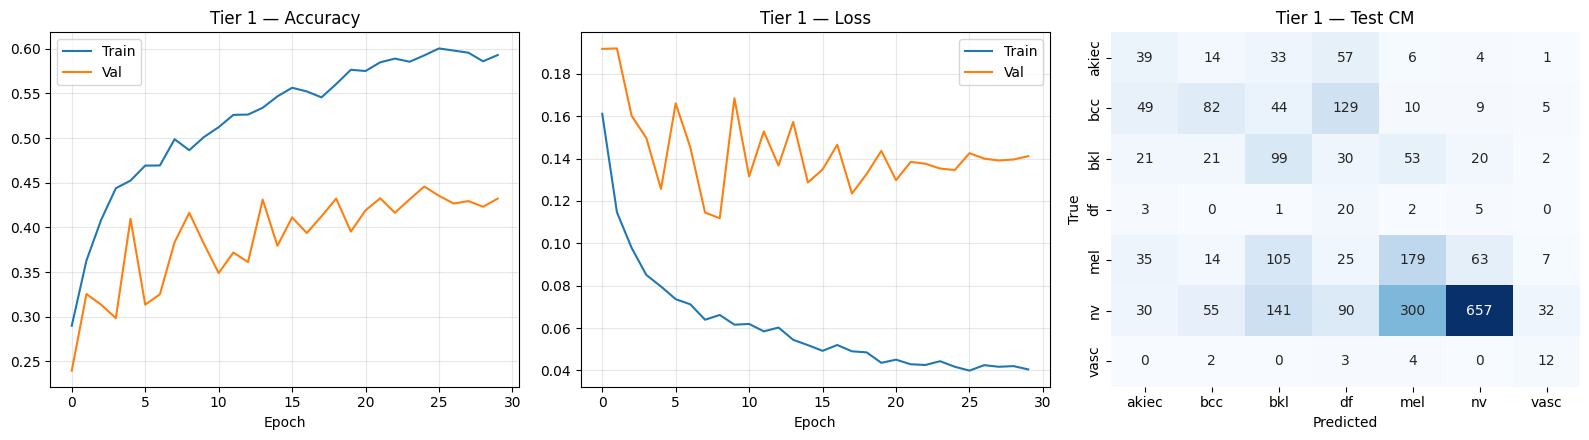


✓ Tier 1 done in 14.1 min

######################################################################
# TIER 2 — FINAL (best Optuna params)
######################################################################
  Params: {'learning_rate': 1.6379674586081077e-05, 'dropout': 0.3539871612489546, 'dense1_units': 2048, 'dense2_units': 512, 'rotation_max': 30, 'zoom_range': 0.10096687016643235, 'focal_gamma': 1.747955411483169}
  Train samples: 10,996 | Steps/epoch: 342
  Total: 58,547,431 | Trainable: 4,205,575
Epoch 1/30
342/342 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step - accuracy: 0.1888 - loss: 0.1710
Epoch 1: val_accuracy improved from None to 0.33942, saving model to /content/drive/MyDrive/Thesis/experiments/inceptionresnetv2/tier2/D_final/best.keras


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()



Epoch 1: finished saving model to /content/drive/MyDrive/Thesis/experiments/inceptionresnetv2/tier2/D_final/best.keras
342/342 ━━━━━━━━━━━━━━━━━━━━ 84s 147ms/step - accuracy: 0.2176 - loss: 0.1591 - val_accuracy: 0.3394 - val_loss: 0.1028 - learning_rate: 1.6380e-05
Epoch 2/30
342/342 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step - accuracy: 0.2848 - loss: 0.1212
Epoch 2: val_accuracy improved from 0.33942 to 0.38468, saving model to /content/drive/MyDrive/Thesis/experiments/inceptionresnetv2/tier2/D_final/best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Thesis/experiments/inceptionresnetv2/tier2/D_final/best.keras
342/342 ━━━━━━━━━━━━━━━━━━━━ 30s 88ms/step - accuracy: 0.3001 - loss: 0.1257 - val_accuracy: 0.3847 - val_loss: 0.1033 - learning_rate: 1.6380e-05
Epoch 3/30
342/342 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step - accuracy: 0.3245 - loss: 0.1114
Epoch 3: val_accuracy improved from 0.38468 to 0.40056, saving model to /content/drive/MyDrive/Thesis/experiments/inceptionresnetv2/ti

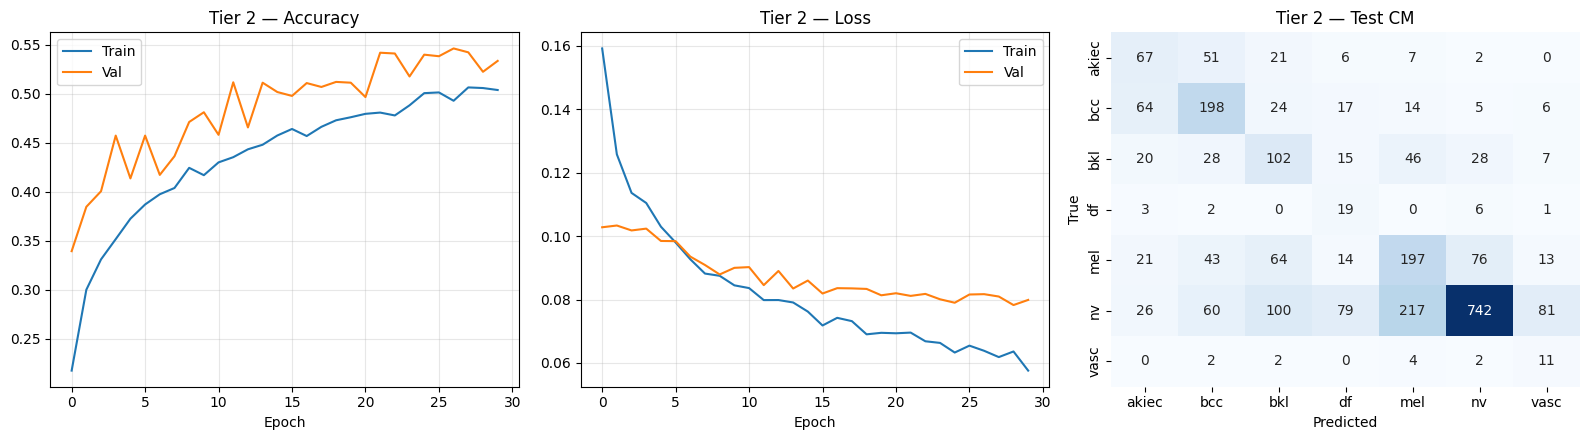


✓ Tier 2 done in 15.4 min

######################################################################
# TIER 3 — FINAL (best Optuna params)
######################################################################
  Params: {'learning_rate': 1.6379674586081077e-05, 'dropout': 0.3539871612489546, 'dense1_units': 2048, 'dense2_units': 512, 'rotation_max': 30, 'zoom_range': 0.10096687016643235, 'focal_gamma': 1.747955411483169}
  Train samples: 14,061 | Steps/epoch: 438
  Total: 58,547,431 | Trainable: 4,205,575
Epoch 1/30
438/438 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step - accuracy: 0.2003 - loss: 0.1498
Epoch 1: val_accuracy improved from None to 0.41842, saving model to /content/drive/MyDrive/Thesis/experiments/inceptionresnetv2/tier3/D_final/best.keras


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()



Epoch 1: finished saving model to /content/drive/MyDrive/Thesis/experiments/inceptionresnetv2/tier3/D_final/best.keras
438/438 ━━━━━━━━━━━━━━━━━━━━ 86s 127ms/step - accuracy: 0.2437 - loss: 0.1391 - val_accuracy: 0.4184 - val_loss: 0.0880 - learning_rate: 1.6380e-05
Epoch 2/30
438/438 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step - accuracy: 0.3068 - loss: 0.1070
Epoch 2: val_accuracy improved from 0.41842 to 0.42040, saving model to /content/drive/MyDrive/Thesis/experiments/inceptionresnetv2/tier3/D_final/best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Thesis/experiments/inceptionresnetv2/tier3/D_final/best.keras
438/438 ━━━━━━━━━━━━━━━━━━━━ 37s 84ms/step - accuracy: 0.3154 - loss: 0.1129 - val_accuracy: 0.4204 - val_loss: 0.0835 - learning_rate: 1.6380e-05
Epoch 3/30
438/438 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step - accuracy: 0.3373 - loss: 0.0983
Epoch 3: val_accuracy improved from 0.42040 to 0.48075, saving model to /content/drive/MyDrive/Thesis/experiments/inceptionresnetv2/ti

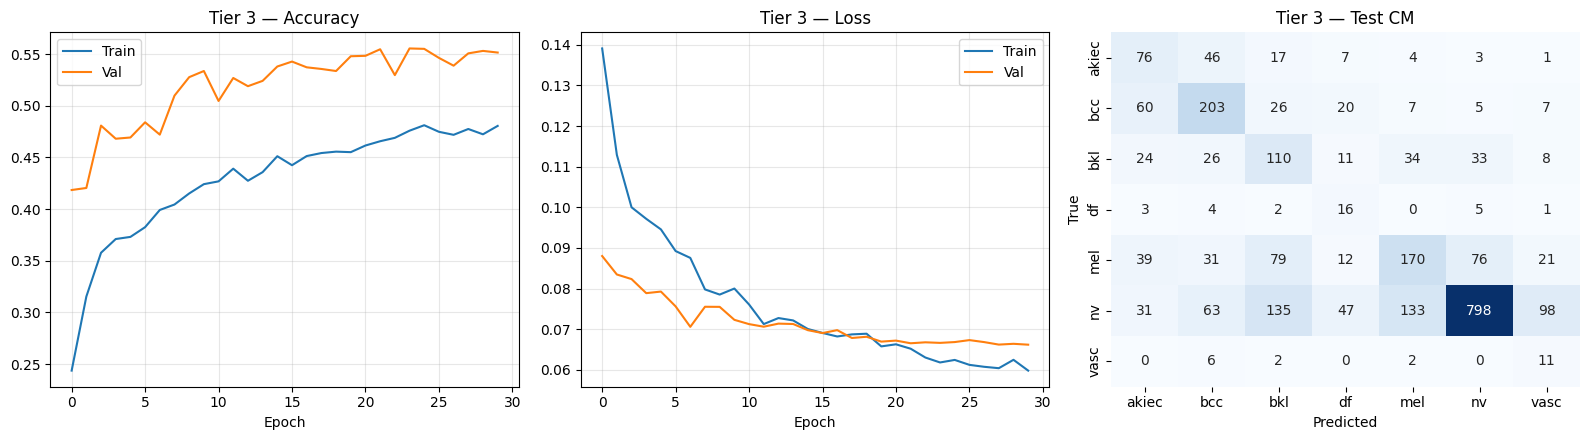


✓ Tier 3 done in 18.7 min

######################################################################
# TIER 4 — FINAL (best Optuna params)
######################################################################
  Params: {'learning_rate': 1.6379674586081077e-05, 'dropout': 0.3539871612489546, 'dense1_units': 2048, 'dense2_units': 512, 'rotation_max': 30, 'zoom_range': 0.10096687016643235, 'focal_gamma': 1.747955411483169}
  Train samples: 17,300 | Steps/epoch: 539
  Total: 58,547,431 | Trainable: 4,205,575
Epoch 1/30
539/539 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step - accuracy: 0.2177 - loss: 0.1412
Epoch 1: val_accuracy improved from None to 0.42596, saving model to /content/drive/MyDrive/Thesis/experiments/inceptionresnetv2/tier4/D_final/best.keras


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()



Epoch 1: finished saving model to /content/drive/MyDrive/Thesis/experiments/inceptionresnetv2/tier4/D_final/best.keras
539/539 ━━━━━━━━━━━━━━━━━━━━ 93s 115ms/step - accuracy: 0.2626 - loss: 0.1328 - val_accuracy: 0.4260 - val_loss: 0.0807 - learning_rate: 1.6380e-05
Epoch 2/30
539/539 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step - accuracy: 0.3138 - loss: 0.1081
Epoch 2: val_accuracy improved from 0.42596 to 0.46566, saving model to /content/drive/MyDrive/Thesis/experiments/inceptionresnetv2/tier4/D_final/best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Thesis/experiments/inceptionresnetv2/tier4/D_final/best.keras
539/539 ━━━━━━━━━━━━━━━━━━━━ 43s 80ms/step - accuracy: 0.3275 - loss: 0.1101 - val_accuracy: 0.4657 - val_loss: 0.0751 - learning_rate: 1.6380e-05
Epoch 3/30
539/539 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step - accuracy: 0.3417 - loss: 0.0948
Epoch 3: val_accuracy improved from 0.46566 to 0.46725, saving model to /content/drive/MyDrive/Thesis/experiments/inceptionresnetv2/ti

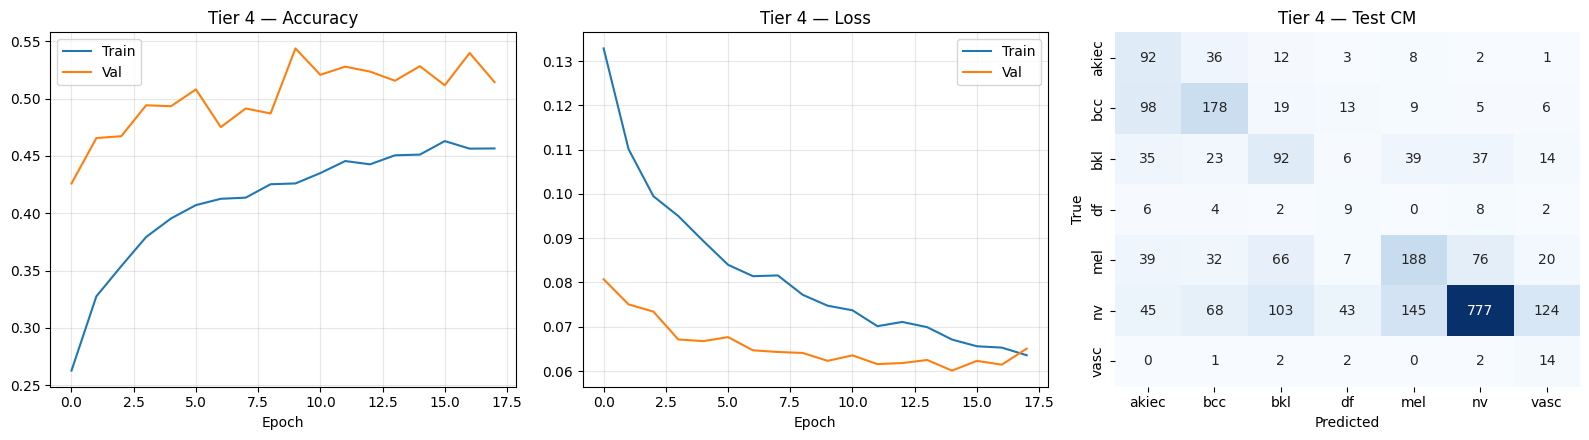


✓ Tier 4 done in 14.0 min

######################################################################
# TIER 5 — FINAL (best Optuna params)
######################################################################
  Params: {'learning_rate': 1.6379674586081077e-05, 'dropout': 0.3539871612489546, 'dense1_units': 2048, 'dense2_units': 512, 'rotation_max': 30, 'zoom_range': 0.10096687016643235, 'focal_gamma': 1.747955411483169}
  Train samples: 20,299 | Steps/epoch: 633
  Total: 58,547,431 | Trainable: 4,205,575
Epoch 1/30
633/633 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step - accuracy: 0.2222 - loss: 0.1309
Epoch 1: val_accuracy improved from None to 0.41127, saving model to /content/drive/MyDrive/Thesis/experiments/inceptionresnetv2/tier5/D_final/best.keras


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()



Epoch 1: finished saving model to /content/drive/MyDrive/Thesis/experiments/inceptionresnetv2/tier5/D_final/best.keras
633/633 ━━━━━━━━━━━━━━━━━━━━ 100s 109ms/step - accuracy: 0.2658 - loss: 0.1242 - val_accuracy: 0.4113 - val_loss: 0.0782 - learning_rate: 1.6380e-05
Epoch 2/30
633/633 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step - accuracy: 0.3171 - loss: 0.0997
Epoch 2: val_accuracy improved from 0.41127 to 0.44502, saving model to /content/drive/MyDrive/Thesis/experiments/inceptionresnetv2/tier5/D_final/best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Thesis/experiments/inceptionresnetv2/tier5/D_final/best.keras
633/633 ━━━━━━━━━━━━━━━━━━━━ 50s 79ms/step - accuracy: 0.3363 - loss: 0.1046 - val_accuracy: 0.4450 - val_loss: 0.0716 - learning_rate: 1.6380e-05
Epoch 3/30
633/633 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step - accuracy: 0.3416 - loss: 0.0897
Epoch 3: val_accuracy improved from 0.44502 to 0.51608, saving model to /content/drive/MyDrive/Thesis/experiments/inceptionresnetv2/t

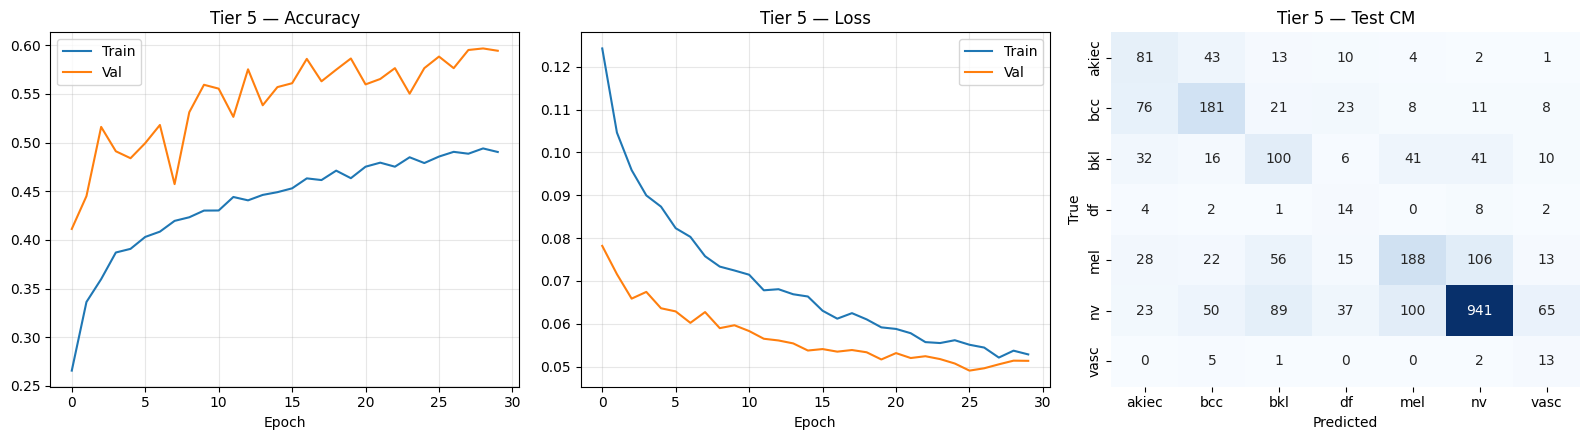


✓ Tier 5 done in 25.2 min

ALL TIERS FINAL EVAL COMPLETE


In [16]:
# ─── Run all tiers ───
all_final_results = {}
for tier in [1, 2, 3, 4, 5]:
    res = train_tier_final(tier)
    if res is not None:
        all_final_results[tier] = res

print('\n' + '='*70)
print('ALL TIERS FINAL EVAL COMPLETE')
print('='*70)


## 7. Summary table


In [17]:
rows = []
for tier, res in sorted(all_final_results.items()):
    row = {
        'tier': tier,
        'epochs': res['epochs_run'],
        'overall_acc': res['overall']['accuracy'] * 100,
        'overall_macro_f1': res['overall']['macro_f1'],
        'overall_weighted_f1': res['overall']['weighted_f1'],
        'overall_auc': res['overall']['auc'],
    }
    for src in ['HAM10000', 'BCN_20000', 'MSK']:
        m = res['per_source'].get(src, {'n_samples': 0})
        if m['n_samples'] > 0:
            row[f'{src}_acc'] = m['accuracy']
            row[f'{src}_f1'] = m['macro_f1']
        else:
            row[f'{src}_acc'] = None
            row[f'{src}_f1'] = None
    row['time_min'] = res['time_minutes']
    rows.append(row)

summary_df = pd.DataFrame(rows)
print(summary_df.to_string(index=False, float_format=lambda x: f'{x:.3f}' if x is not None else 'N/A'))

summary_dir = EXPERIMENTS_DIR / 'summary'
summary_dir.mkdir(parents=True, exist_ok=True)
summary_df.to_csv(summary_dir / 'final_summary.csv', index=False)
print(f'\nSaved: {summary_dir / "final_summary.csv"}')


 tier  epochs  overall_acc  overall_macro_f1  overall_weighted_f1  overall_auc  HAM10000_acc  HAM10000_f1  BCN_20000_acc  BCN_20000_f1  MSK_acc  MSK_f1  time_min
    1      30       43.295             0.322                0.482        0.801         0.588        0.435          0.325         0.240    0.322   0.155    14.131
    2      30       53.164             0.397                0.565        0.851         0.612        0.404          0.475         0.357    0.529   0.267    15.390
    3      30       55.074             0.404                0.585        0.852         0.604        0.386          0.518         0.383    0.460   0.233    18.659
    4      18       53.721             0.389                0.573        0.848         0.568        0.360          0.510         0.366    0.425   0.221    13.959
    5      30       60.406             0.431                0.627        0.861         0.669        0.426          0.553         0.392    0.540   0.273    25.181

Saved: /content/drive/MyDri